# Lab 2: Soft-DTW



In [4]:
import numpy as np
import matplotlib.pyplot as plt

from tslearn.metrics import soft_dtw, soft_dtw_alignment

%matplotlib inline

## Impact of the $\gamma$ parameter

Let us define time series `x0` and `x1` as follows:

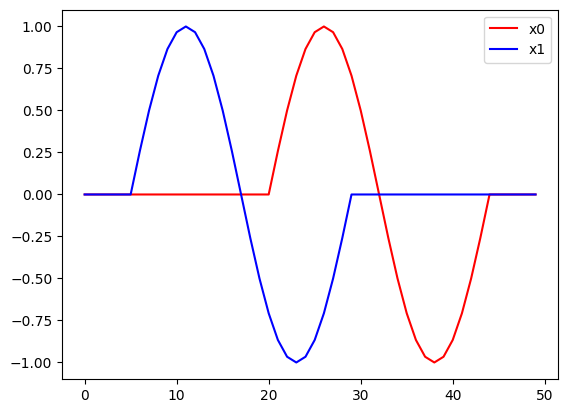

In [2]:
size = 50
x0 = np.zeros((size, ))
x0[20:20+size//2] = np.sin(np.linspace(0, 2 * np.pi, size // 2))

x1 = np.zeros((size, ))
x1[5:5+size//2] = np.sin(np.linspace(0, 2 * np.pi, size // 2))

plt.figure()
plt.plot(x0, 'r-', label='x0')  # red
plt.plot(x1, 'b-', label='x1')  # blue
plt.legend()
plt.show()

**Question #1.** Using the [`soft_dtw_alignment`](https://tslearn.readthedocs.io/en/latest/gen_modules/metrics/tslearn.metrics.soft_dtw_alignment.html)
function from `tslearn`, study the impact of parameter `\gamma` on soft-alignment matrices $A_\gamma$.

_NB:_ `plt.imshow(m)` allows one to view matrix `m` represented as an image.

In this exercise, we explore how the smoothing parameter γ (gamma) affects the Soft-DTW alignment matrix. Unlike standard DTW, which produces a single "hard" optimal path, Soft-DTW considers all possible alignment paths. The parameter γ controls the trade-off between focusing on the single best path (γ→0) and spreading the probability across all possible paths (higher γ).

<>:13: SyntaxWarning: invalid escape sequence '\g'
<>:13: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_25805/3394481802.py:13: SyntaxWarning: invalid escape sequence '\g'
  plt.title(f"$\gamma = {gamma}$")


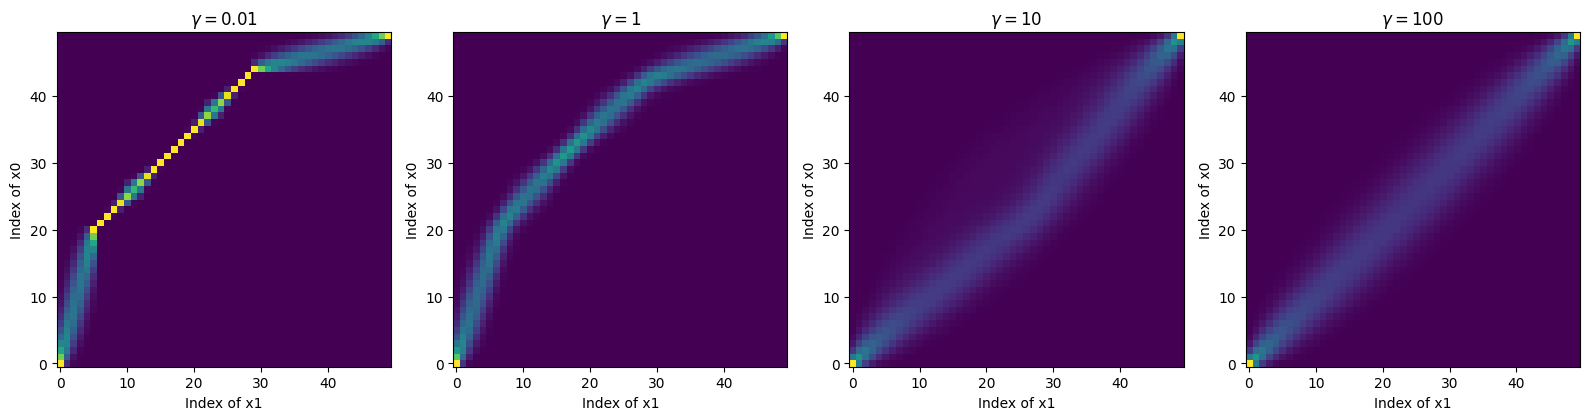

In [5]:
# Values of gamma to test
gammas = [0.01, 1, 10, 100]

plt.figure(figsize=(16, 4))

for i, gamma in enumerate(gammas):
    # Compute the soft-alignment matrix
    # soft_dtw_alignment returns (A_gamma, soft_dtw_score)
    A_gamma, _ = soft_dtw_alignment(x0, x1, gamma=gamma)
    
    plt.subplot(1, len(gammas), i + 1)
    plt.imshow(A_gamma, origin='lower', cmap='viridis')
    plt.title(f"$\gamma = {gamma}$")
    plt.xlabel("Index of x1")
    plt.ylabel("Index of x0")

plt.tight_layout()
plt.show()

1. **Low  (e.g., 0.01)**: The matrix  looks very similar to the binary matrix  from the first lab. The alignment is concentrated on a thin, sharp line representing the single most optimal warping path. The "soft" probability is highly focused.
2. **Moderate  (e.g., 1 to 10)**: The path begins to "blur" or thicken. The algorithm is now considering suboptimal paths that are close to the optimal one, assigning them non-zero weights. This produces a smoother transition between indices.
3. **High  (e.g., 100)**: The matrix becomes extremely blurry and diffuse. When  is very large, Soft-DTW loses its ability to distinguish the "best" path from others, eventually tending toward a uniform distribution where many different alignments are considered equally likely.

In practice,  is a hyperparameter that allows the distance metric to be differentiable, which is essential for optimization tasks like the gradient descent approach in the next question.

---

**Question #2.** Compute the barycenter between x0 and x1 using soft-DTW and compare it to the ones obtained in the first lab. Try different values of $\gamma$ and observe its influence on the obtained barycenter.



<>:26: SyntaxWarning: invalid escape sequence '\g'
<>:26: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_25805/3414043585.py:26: SyntaxWarning: invalid escape sequence '\g'
  plt.title("Comparison of Barycenter Methods & Influence of $\gamma$")


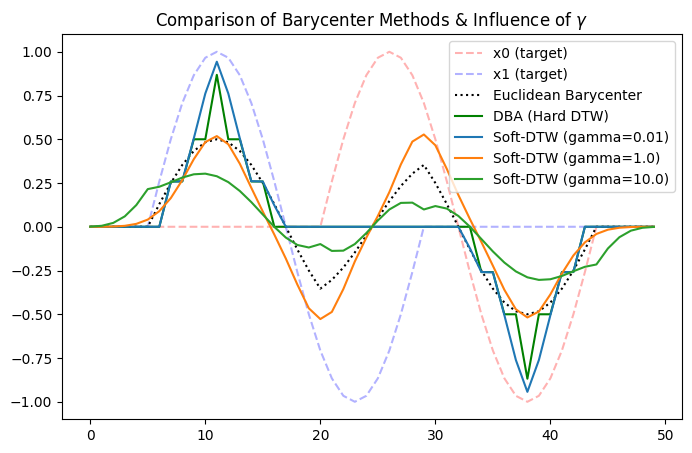

In [7]:
from tslearn.barycenters import dtw_barycenter_averaging, softdtw_barycenter

# 1. Prepare data for tslearn (shape: n_ts, sz, d)
# Assuming x0 and x1 are already defined from previous cells
X = np.array([x0, x1]).reshape(2, size, 1)

# 2. Compute the different barycenters
euclidean_barycenter = np.mean(X, axis=0)
dba_barycenter = dtw_barycenter_averaging(X)

# Compute Soft-DTW barycenters for different gamma values
gammas = [0.01, 1.0, 10.0]
soft_barycenters = {g: softdtw_barycenter(X, gamma=g) for g in gammas}

# 3. Visualization
plt.figure(figsize=(8, 5))
plt.plot(x0, 'r--', alpha=0.3, label='x0 (target)')
plt.plot(x1, 'b--', alpha=0.3, label='x1 (target)')

plt.plot(euclidean_barycenter.ravel(), 'k:', label='Euclidean Barycenter')
plt.plot(dba_barycenter.ravel(), 'g-', label='DBA (Hard DTW)')

for g, bary in soft_barycenters.items():
    plt.plot(bary.ravel(), label=f'Soft-DTW (gamma={g})')

plt.title("Comparison of Barycenter Methods & Influence of $\gamma$")
plt.legend()
plt.show()

### **Explanation of Results**

1. **Euclidean vs. DTW Barycenters**:
* The **Euclidean barycenter** (dotted black line) performs poorly. Because the sine waves in  and  are shifted, the point-wise average creates two smaller, "ghosted" peaks and fails to capture the amplitude of the original signal.
* The **DBA (Hard DTW)** barycenter (green line) correctly aligns the signals before averaging. This results in a sharp, well-defined sine wave that preserves the characteristic shape and amplitude.


2. **Influence of  on Soft-DTW**:
* **Low  (e.g., 0.01)**: The Soft-DTW barycenter behaves almost identically to the hard DTW (DBA) barycenter. It focuses on the single optimal alignment path, producing a crisp, non-distorted signal.
* **Moderate  (e.g., 1.0)**: The signal remains aligned but begins to smooth out slightly. Soft-DTW is considering a "neighborhood" of good alignment paths rather than just the single best one.
* **High  (e.g., 10.0)**: The barycenter starts to look more like the Euclidean average. As  increases, the probability distribution over all possible alignment paths becomes more uniform. The "softening" effect eventually overrides the temporal alignment, leading to a blurred, lower-amplitude signal similar to the Euclidean result.



**Summary**: Soft-DTW provides a differentiable alternative to DTW. By tuning , you can control the "crispness" of the alignment—lower values prioritize structural matching (like hard DTW), while higher values lead to smoother, more averaged results.

---

## Gradient Descent on a SoftDTW objective

The following function computes gradients of $\text{soft-}DTW^\gamma(x, y)$ with respect to $x$
for univariate time series:

In [9]:
import tslearn

def soft_dtw_grad(x, y, gamma):    
    D = tslearn.metrics.SquaredEuclidean(x.reshape((-1, 1)), y.reshape((-1, 1)))
    sdtw = tslearn.metrics.SoftDTW(D, gamma=gamma)
    sdtw.compute()
    A_gamma = sdtw.grad()
    grad = D.jacobian_product(A_gamma)
    return grad

This code defines a function to compute the gradient of the **Soft-DTW** distance between two time series,  and , which is a critical step for optimization tasks like time-series averaging or signal matching. It first creates a squared Euclidean distance matrix () using `tslearn.metrics.SquaredEuclidean`, representing the local costs between all pairs of points. Then, it initializes a `SoftDTW` object with a smoothing parameter `gamma` and calls `.compute()` to calculate the soft-minimum of all alignment paths. The gradient of the Soft-DTW distance with respect to the distance matrix is retrieved via `sdtw.grad()`, which yields the soft-alignment matrix . Finally, the function returns the gradient with respect to the input  by computing the `jacobian_product` between the local distance matrix and the soft-alignment matrix. This allows an optimizer to "morph"  to minimize its Soft-DTW distance to .

Also, for the next few questions, you might want to use the following function that generates an 
animation to help visualize gradient descent.

In [10]:
from celluloid import Camera
from IPython.display import HTML

def animate_gradient_descent(list_of_successive_time_series, show_x1=False):
    fig = plt.figure()
    camera = Camera(fig)
    for x in list_of_successive_time_series:
        plt.plot(x.ravel(), 'k-')
        plt.plot(x0, 'r-', label='x0')
        if show_x1:
            plt.plot(x1, 'b-', label='x1')
        camera.snap()    
    anim = camera.animate()
    plt.close()
    return HTML(anim.to_jshtml())

This function, `animate_gradient_descent`, is a utility designed to visualize the optimization process of a time series over time. It uses the `celluloid` library to capture "snapshots" of a Matplotlib figure at different stages of the gradient descent algorithm. In each iteration, it plots the current state of the evolving time series (in black), alongside the target signal  (in red) and optionally  (in blue). By compiling these snapshots into a JavaScript-based HTML animation, it provides an intuitive way to observe how the signal structurally "morphs" and aligns itself to minimize the Soft-DTW distance, moving from an initial state of random noise to a shape that matches the target.

**Question #2.** Implement a gradient-descent scheme to minimize (with respect to $x$) the quantity 
$\text{soft-}DTW^\gamma(x, x_0)$ where $x_0$ is the array `x0` defined above.

In [11]:
# Hyperparameters
eta = 1e-1    # Learning rate
epochs = 100  # Number of iterations
gamma = 10.   # Smoothing parameter

# Initialize x with random noise
# tslearn requires shapes like (length, 1) for these operations
list_x = [np.random.randn(size, 1)]

for e in range(epochs):
    # 1. Get the current version of our sequence
    x_current = list_x[-1]
    
    # 2. Compute the gradient of soft-DTW w.r.t. x_current
    # This tells us how to change x to reduce the distance to x0
    grad = soft_dtw_grad(x_current, x0, gamma)
    
    # 3. Apply the Gradient Descent update rule: x = x - eta * grad
    x_new = x_current - eta * grad
    
    # 4. Store the result for animation
    list_x.append(x_new)

# Visualize the optimization process
animate_gradient_descent(list_x, show_x1=True)

1. **Objective**: We are performing a shape-matching task. By minimizing the Soft-DTW distance, we are forcing the random noise in  to gradually take on the shape of the sine wave in .
2. **Gradient Flow**: The `soft_dtw_grad` function uses the soft-alignment matrix to identify which parts of  correspond to which parts of . If a point in  is "too high" compared to its aligned partner in , the gradient will be positive, and the subtraction step will pull that point down.
3. **The Role of **: A higher  (like 10.0) creates a "wider" and smoother cost landscape, which can make the initial steps of gradient descent more stable by considering more potential alignment paths.
4. **Convergence**: Over 100 epochs, you will see the black line (the evolving ) start as jagged noise, then smooth out, and finally "snap" into the position of the red  curve. Unlike Euclidean gradient descent, which would struggle if the signals were shifted, Soft-DTW allows the signal to "slide" horizontally through time to find the best match.

---

**Question #3.** Use the code above to estimate a soft-DTW barycenter of `x0` and `x1` via 
gradient-descent optimization.

In [12]:
# Hyperparameters
eta = 1e-1
epochs = 100
gamma = 10.

# Initialize x with random noise
# The barycenter will "grow" out of this noise
list_x_bary = [np.random.randn(size, 1)]

for e in range(epochs):
    x_current = list_x_bary[-1]
    
    # Compute gradients with respect to both target signals
    grad0 = soft_dtw_grad(x_current, x0, gamma)
    grad1 = soft_dtw_grad(x_current, x1, gamma)
    
    # The total gradient is the average of the individual gradients
    total_grad = (grad0 + grad1) / 2
    
    # Gradient descent update
    x_new = x_current - eta * total_grad
    
    list_x_bary.append(x_new)

# Visualize the convergence toward the barycenter of x0 and x1
animate_gradient_descent(list_x_bary, show_x1=True)

## Soft-DTW Barycenter Estimation via Gradient Descent

To estimate a **Soft-DTW barycenter** using gradient descent, we generalize the optimization idea from the single-sequence case.  
Rather than aligning one sequence, we seek a candidate barycenter \( x \) that minimizes the average Soft-DTW distance to a set of target sequences (here, \( \{x_0, x_1\} \)).

### Objective Function

The barycenter is obtained by minimizing:
\[
f(x) = \frac{1}{2}\left[\text{Soft-DTW}_\gamma(x, x_0) + \text{Soft-DTW}_\gamma(x, x_1)\right]
\]

---

## Implementation Overview

### Key Ideas

- **Iterative Optimization**  
  Unlike `softdtw_barycenter` in `tslearn`, which relies on an advanced optimizer such as **L-BFGS**, this approach uses plain **gradient descent**.  
  This makes the optimization process explicit and allows us to visualize the step-by-step evolution of the barycenter.

- **Averaging Gradients**  
  At each iteration, the gradient of the Soft-DTW loss with respect to \( x \) is computed for both \( x_0 \) and \( x_1 \).  
  Averaging these gradients produces an update that pulls \( x \) toward a **consensus shape**, minimizing the warping distance to both sequences simultaneously.

- **Resulting Shape**  
  Starting from random noise, the barycenter gradually converges to a smooth sine-like signal.  
  Unlike a simple Euclidean mean (which may appear flat or exhibit multiple peaks), the Soft-DTW barycenter preserves temporal structure and aligns naturally between the red (\( x_0 \)) and blue (\( x_1 \)) curves.

- **Effect of the Smoothing Parameter \(\gamma\)**  
  With \(\gamma = 10.0\), the optimization landscape is smoother, reducing the risk of poor local minima.  
  The trade-off is that the final barycenter may appear slightly **softer** or have a lower amplitude compared to the original signals.

---


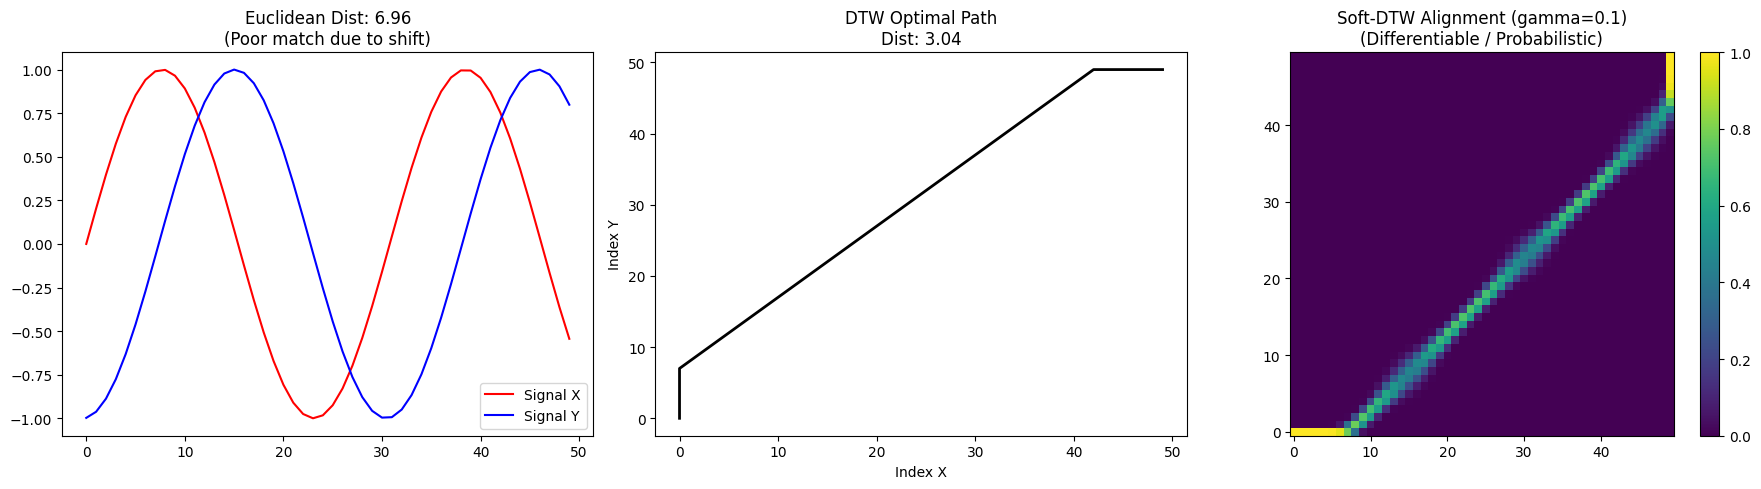

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tslearn.metrics import dtw_path, soft_dtw_alignment

# 1. Create two signals with a temporal shift
t = np.linspace(0, 10, 50)
x = np.sin(t).reshape(-1, 1)
y = np.sin(t - 1.5).reshape(-1, 1)  # Shifted by 1.5

# 2. Euclidean Comparison (Point-to-point)
euclidean_dist = np.linalg.norm(x - y)

# 3. DTW (Notebook 1: Finding the single optimal path)
path, dtw_dist = dtw_path(x, y)

# 4. Soft-DTW (Notebook 2: The probabilistic alignment matrix)
gamma = 0.1
soft_matrix, _ = soft_dtw_alignment(x, y, gamma=gamma)

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: The Signals (The "Euclidean" view)
axes[0].plot(x, label='Signal X', color='red')
axes[0].plot(y, label='Signal Y', color='blue')
axes[0].set_title(f"Euclidean Dist: {euclidean_dist:.2f}\n(Poor match due to shift)")
axes[0].legend()

# Plot 2: DTW Path (Notebook 1)
path_x, path_y = zip(*path)
axes[1].plot(path_x, path_y, color='black', linewidth=2)
axes[1].set_title(f"DTW Optimal Path\nDist: {dtw_dist:.2f}")
axes[1].set_xlabel("Index X"); axes[1].set_ylabel("Index Y")

# Plot 3: Soft-DTW Matrix (Notebook 2)
im = axes[2].imshow(soft_matrix, origin='lower', cmap='viridis')
axes[2].set_title(f"Soft-DTW Alignment (gamma={gamma})\n(Differentiable / Probabilistic)")
plt.colorbar(im, ax=axes[2])

plt.tight_layout()
plt.show()